In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import seaborn as sns

In [2]:
dataset = pd.read_csv('../data/interim/sequences.csv', index_col='tcr_id')

In [3]:
print('Number of complexes:', len(dataset))

Number of complexes: 2636


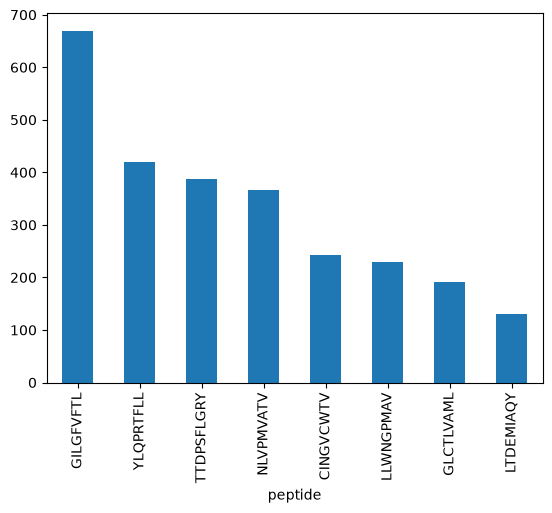

In [4]:
dataset['peptide'].value_counts().plot.bar()
plt.show()

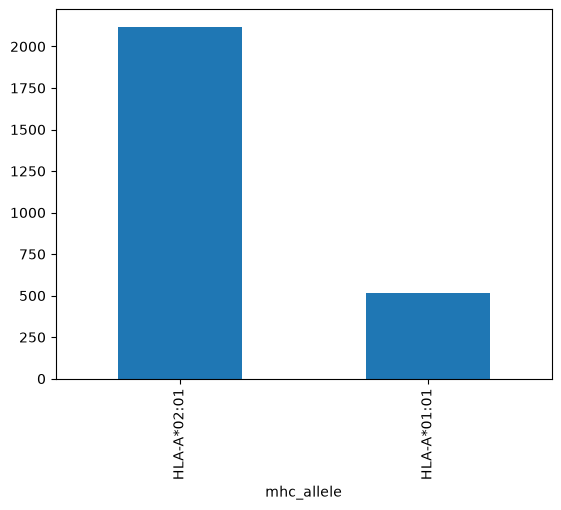

In [5]:
dataset['mhc_allele'].value_counts().plot.bar()
plt.show()

In [6]:
dataset.value_counts(['peptide', 'mhc_allele'])

peptide     mhc_allele 
GILGFVFTL   HLA-A*02:01    670
YLQPRTFLL   HLA-A*02:01    419
TTDPSFLGRY  HLA-A*01:01    387
NLVPMVATV   HLA-A*02:01    366
CINGVCWTV   HLA-A*02:01    243
LLWNGPMAV   HLA-A*02:01    229
GLCTLVAML   HLA-A*02:01    192
LTDEMIAQY   HLA-A*01:01    130
Name: count, dtype: int64

In [7]:
dataset[['cdr1_alpha', 'cdr2_alpha', 'cdr3_alpha', 'cdr1_beta', 'cdr2_beta', 'cdr3_beta']].value_counts()

cdr1_alpha  cdr2_alpha  cdr3_alpha     cdr1_beta  cdr2_beta  cdr3_beta      
DSSSTY      IFSNMDM     AESIGKLI       SQVTM      ANQGSEA    SVGSGGTNEKLF       2
TISGNEY     GLKNN       IVRVEGNNRLA    DFQATT     SNEGSKA    SARDQPAQNTGELF     1
                        IVRVFRKKGQNFV  SGHDT      YYEEEE     ASSLAHQTYEQY       1
                        IVRVGAAGNKLT   DFQATT     SNEGSKA    SARDVPGTTLGGELF    1
                        IVRVGGDSWGKLQ  MNHEY      SMNVEV     ASSSLNTEAF         1
                                                                               ..
NSASDY      IRSNMDK     AENMGGGSQGNLI  LNHDA      SQIVND     ASSDRAGNEQF        1
                                                             ASSIRAGETQY        1
                                                             ASSTRAGDTQY        1
                                                             ASSVRAGETQY        1
                        AENIFSGGYNKLI  SNHLY      FYNNEI     ASSDTQGSQPQH       1
Name: count, Length: 

In [8]:
dataset.query(
    "cdr1_alpha == 'DSSSTY' and cdr2_alpha == 'IFSNMDM' and cdr3_alpha == 'AESIGKLI'"
    " and cdr1_beta == 'SQVTM' and cdr2_beta == 'ANQGSEA' and cdr3_beta == 'SVGSGGTNEKLF'"
)

,v_alpha,j_alpha,v_beta,j_beta,cdr1_alpha,cdr2_alpha,cdr3_alpha,cdr1_beta,cdr2_beta,cdr3_beta,tcr_alpha_chain,tcr_beta_chain,peptide,mhc_allele,mhc_chain_1,mhc_chain_2
tcr_id,,,,,,,,,,,,,,,,
2_15_H13_180_GLCTLVAML,TRAV5*01,TRAJ23*01,TRBV29-1*02,TRBJ1-4*01,DSSSTY,IFSNMDM,AESIGKLI,SQVTM,ANQGSEA,SVGSGGTNEKLF,GEDVEQSLFLSVREGDSSVINCTYTDSSSTYLYWYKQEPGAGLQLL...,SAVISQKPSRDICQRGTSLTIQCQVDSQVTMMFWYRQQPGQSLTLI...,GLCTLVAML,HLA-A*02:01,GSHSMRYFFTSVSRPGRGEPRFIAVGYVDDTQFVRFDSDAASQRME...,IQRTPKIQVYSRHPAENGKSNFLNCYVSGFHPSDIEVDLLKNGERI...
2_16_F5_64_GLCTLVAML,TRAV5*01,TRAJ34*01,TRBV29-1*01,TRBJ1-4*01,DSSSTY,IFSNMDM,AESIGKLI,SQVTM,ANQGSEA,SVGSGGTNEKLF,GEDVEQSLFLSVREGDSSVINCTYTDSSSTYLYWYKQEPGAGLQLL...,SAVISQKPSRDICQRGTSLTIQCQVDSQVTMMFWYRQQPGQSLTLI...,GLCTLVAML,HLA-A*02:01,GSHSMRYFFTSVSRPGRGEPRFIAVGYVDDTQFVRFDSDAASQRME...,IQRTPKIQVYSRHPAENGKSNFLNCYVSGFHPSDIEVDLLKNGERI...


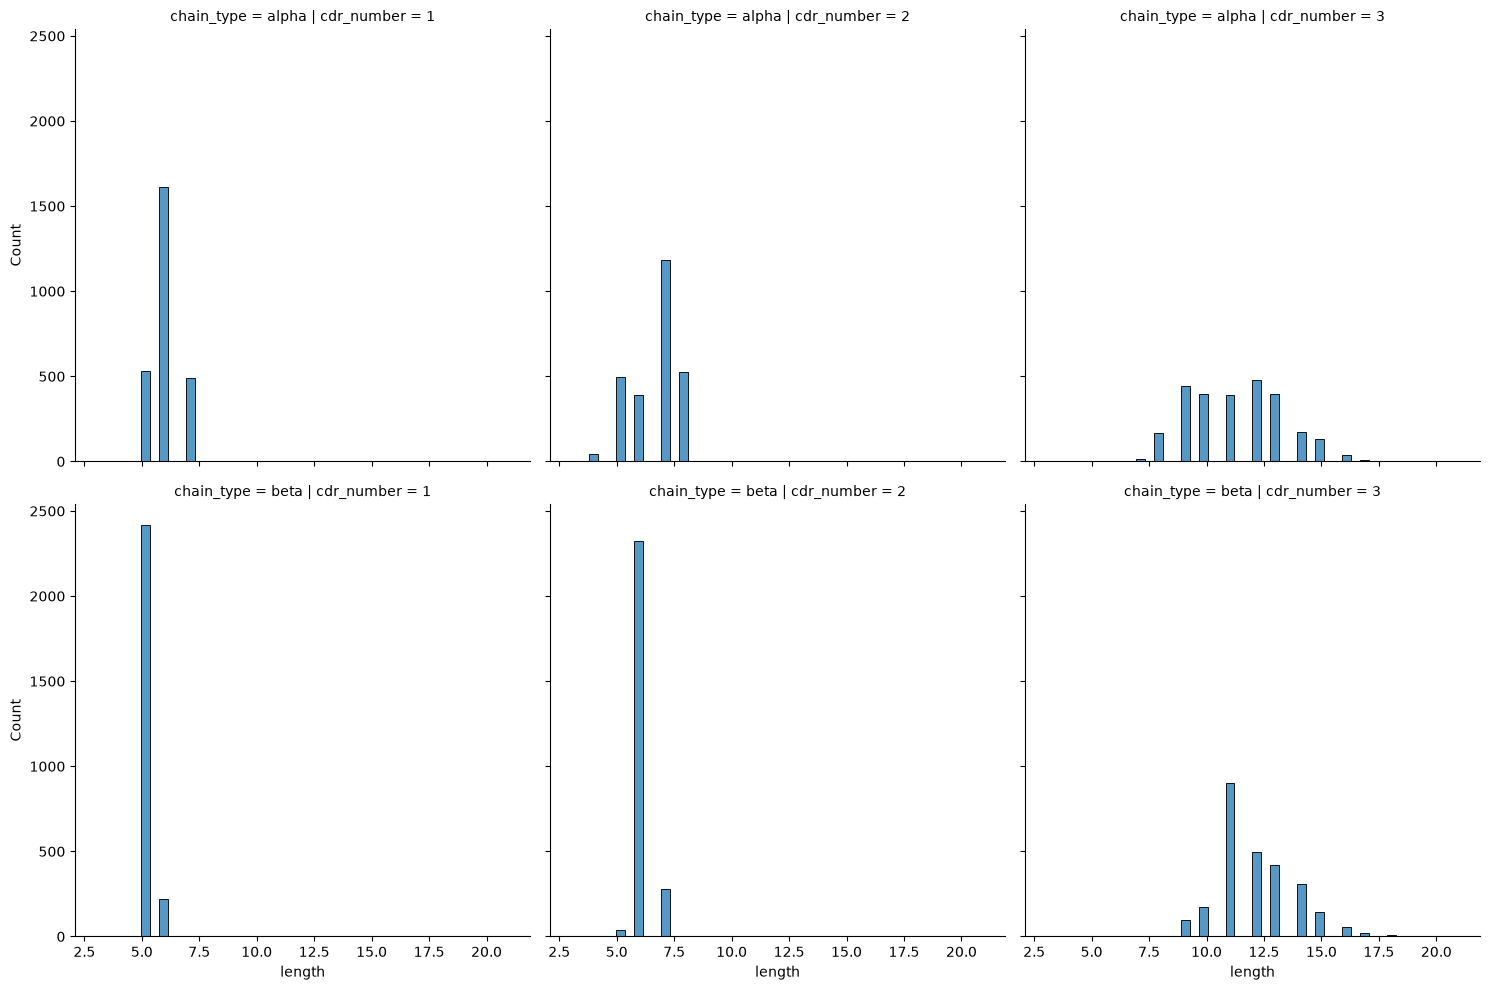

In [9]:
cdrs = dataset[['cdr1_alpha', 'cdr2_alpha', 'cdr3_alpha', 'cdr1_beta', 'cdr2_beta', 'cdr3_beta']]
cdrs = cdrs.melt(value_vars=cdrs.columns, var_name='cdr_type', value_name='sequence')
cdrs['length'] = cdrs['sequence'].map(len)

cdrs[['cdr_number', 'chain_type']] = cdrs['cdr_type'].str.split('_').apply(pd.Series)
cdrs['cdr_number'] = cdrs['cdr_number'].str.replace('cdr', '').astype(int)

sns.displot(cdrs, x='length', row='chain_type', col='cdr_number')
plt.show()

In [10]:
plot_df = pd.concat(
    [
        dataset[[source_gene_type, target_gene_type]]
        .value_counts()
        .reset_index()
        .rename({source_gene_type: 'source', target_gene_type: 'target'}, axis='columns')
        for source_gene_type, target_gene_type in itertools.pairwise(['v_alpha', 'j_alpha', 'v_beta', 'j_beta'])
    ]
)

unique_source_target = list(np.unique(plot_df[['source', 'target']].to_numpy().flatten()))

mapping_dict = {k: v for v, k in enumerate(unique_source_target)}

plot_df['source'] = plot_df['source'].map(mapping_dict)
plot_df['target'] = plot_df['target'].map(mapping_dict)

fig = go.Figure(
    data=[
        go.Sankey(
            node={
                'pad': 20,
                'thickness': 30,
                'line': {'color': 'black', 'width': 0.5},
                'label': unique_source_target,
            },
            link={
                'source': plot_df['source'],
                'target': plot_df['target'],
                'value': plot_df['count'],
            },
        )
    ]
)

fig.update_layout(title_text='Sankey diagram of TCR gene usage', font_size=10, width=1400, height=900)
fig.show()